## Data preparation
1. Clip the land use map into tiles
2. Clip the NAIP images into tiles
3. Split the data into two major componments, training and testing

By Xiaojiang Li, Dec 6, 2024
Update by Xiaojiang Li, Oct 13, 2026

### 0. Set up the environment (local Jupyter or optional Colab)

**Local workflow (default):** Open this notebook in JupyterLab, Jupyter Notebook, or VS Code using your Python environment. Run the setup cells first. They install only missing dependencies into the active kernel; set `INSTALL_MISSING_PACKAGES=False` if you manage packages yourself. Restart the kernel if installation requests it. The notebooks use `data/lab9` under the repository by default, whether launched from the repository root or the lab folder. Set `LOCAL_DATA_ROOT` to an absolute folder path if your data live elsewhere, and use the same path in both notebooks.

Run **Part 1 before Part 2** to prepare the paired training and validation tiles. Existing downloaded rasters are reused. Downloads and tile generation can take time and disk space.

**Optional Colab workflow:** The same cells run in Colab using `/content/lab9`. Google Drive is disabled by default. Set `USE_GOOGLE_DRIVE=True` in both notebooks if you want to mount Drive and share persistent data between their separate runtimes. Otherwise, transfer the prepared `dataset` folder between runtimes and retain your outputs before a runtime closes. No Colab import or Drive login is required locally.


In [1]:
import importlib.util
import subprocess
import sys

INSTALL_MISSING_PACKAGES = True  # Set False to manage your environment yourself.
packages = {'numpy': 'numpy', 'rasterio': 'rasterio', 'shapely': 'shapely', 'skimage': 'scikit-image', 'scipy': 'scipy', 'PIL': 'pillow', 'matplotlib': 'matplotlib'}
missing = [package for module, package in packages.items()
           if importlib.util.find_spec(module) is None]
if missing:
    if not INSTALL_MISSING_PACKAGES:
        raise ImportError('Install these packages in this notebook kernel: ' + ', '.join(missing))
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *missing])
else:
    print('Required packages are already installed.')


Required packages are already installed.


In [2]:
from pathlib import Path
import sys
import random
import numpy as np

IN_COLAB = 'google.colab' in sys.modules
USE_GOOGLE_DRIVE = False  # Optional: enable only when running in Colab.
# Change this to an absolute path to use your own local data folder.
repository_dir = Path.cwd().resolve()
if repository_dir.name == 'lab9-image-segmentation':
    repository_dir = repository_dir.parent
LOCAL_DATA_ROOT = repository_dir / 'data' / 'lab9'

if IN_COLAB and USE_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_ROOT = Path('/content/drive/MyDrive/ai-urban-sustainability/lab9')
elif IN_COLAB:
    DATA_ROOT = Path('/content/lab9')
else:
    DATA_ROOT = Path(LOCAL_DATA_ROOT).expanduser().resolve()
DATA_ROOT.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR = DATA_ROOT / 'outputs'
OUTPUT_DIR.mkdir(exist_ok=True)
random.seed(42)
np.random.seed(42)
print('Environment:', 'Colab' if IN_COLAB else 'local Python')
print('Data folder:', DATA_ROOT)
print('Output folder:', OUTPUT_DIR)
print('Python:', sys.version.split()[0])


Environment: local Python
Data folder: /Users/jianglix/Dropbox/xiaojiang/Teaching/Penn/AI-Urban-Sustainability/ai-urban-sustainability/data/lab9
Output folder: /Users/jianglix/Dropbox/xiaojiang/Teaching/Penn/AI-Urban-Sustainability/ai-urban-sustainability/data/lab9/outputs
Python: 3.14.7


In [3]:
# Dependencies are installed in the setup cells above.


In [4]:
import os, os.path
from pathlib import Path
import shutil
import rasterio as rio
import rasterio
from rasterio.windows import get_data_window
from rasterio.windows import Window
import rasterio.mask
import json
from shapely.geometry import Polygon
import random
import numpy as np
import argparse

### 1. Clip the land use/cover map

In [5]:
def raster2tiles(input_value_raster, tile_width_in, tile_height_in, outfolder): 
    '''This is function is used to clip the raster data into many smaller 
    fixed size of tiles
    
    Parameter: 
        input_value_raster: the filename of the input raster
        tile_width_in: the specified tile width
        tile_height_in: the specified tile height
        outfolder: the ouput dsm folder
    '''
    
    lu_dataset = rasterio.open(input_value_raster)
    lu_img = lu_dataset.read()
    
    # height and width of the raster
    height, width = lu_dataset.shape

    # split the large raser into number of tiles, tile size is 2000*2000
    tile_width = tile_width_in
    tile_height = tile_height_in

    tile_num_col = int(width/tile_width + 0.5)
    tile_num_row = int(height/tile_height + 0.5)

    # the output folder
    if not os.path.exists(outfolder): os.mkdir(outfolder)

    # create each tile
    for i in range(tile_num_row):
        # re-initiate the tile width when reach the right boundary
        tile_width = tile_width_in
        row_start = i*tile_height

        # loop each column
        for j in range(tile_num_col):
            # print('The i and j is:', i, j)
            tilename = os.path.join(outfolder, 'row%s-col%s.tif'%(i, j))
            
            col_start = j*tile_width
            row_end = (i + 1)*tile_height
            col_end = (j + 1)*tile_width
            
            # deal with the right boundary
            if row_end > height - 1: tile_height = height - row_start
            if col_end > width - 1: tile_width = width - col_start
            
            # window = get_data_window(lu_dataset.read(1, masked=True))
            window = Window(col_off=col_start, row_off=row_start, width=tile_width, height=tile_height)
            
            kwargs = lu_dataset.meta.copy()
            kwargs.update({
                'height': window.height,
                'width': window.width,
                'transform': rasterio.windows.transform(window, lu_dataset.transform)})
            
            img_window = lu_dataset.read(window=window)
            if img_window.min() <= 0: continue
            with rasterio.open(tilename, 'w', **kwargs) as dst:
                dst.write(img_window)


Download the supplied Philadelphia NAIP imagery and land use/cover reference raster in the next cell. Existing complete files are reused. Keep the original multiclass reference labels for the homework.


In [6]:
from urllib.request import urlopen

root = str(DATA_ROOT)
DATA_URL = 'https://utilitiesfiles.s3.us-east-1.amazonaws.com/penn-class/ai-urban-sustainability/data/'

def download_file(url, destination):
    destination = Path(destination)
    if destination.exists() and destination.stat().st_size > 0:
        print('Using existing file:', destination.name)
        return
    temporary = destination.with_suffix(destination.suffix + '.part')
    print('Downloading:', url)
    with urlopen(url, timeout=120) as response, temporary.open('wb') as output:
        shutil.copyfileobj(response, output)
    temporary.replace(destination)

landcover_file = str(DATA_ROOT / 'lu_phily.tif')
naip_file = str(DATA_ROOT / 'naip-philly.tif')
download_file(DATA_URL + 'lu_phily.tif', landcover_file)
download_file(DATA_URL + 'naip-philly.tif', naip_file)

folder1 = str(DATA_ROOT / 'dataset')
foldertraining = str(Path(folder1) / 'trainning')  # Keep the existing folder spelling.
train_label_folder = str(Path(foldertraining) / 'labels')
Path(train_label_folder).mkdir(parents=True, exist_ok=True)
tile_width = 256
tile_height = 256
raster2tiles(landcover_file, tile_width, tile_height, train_label_folder)


Downloading: https://utilitiesfiles.s3.us-east-1.amazonaws.com/penn-class/ai-urban-sustainability/data/lu_phily.tif
Downloading: https://utilitiesfiles.s3.us-east-1.amazonaws.com/penn-class/ai-urban-sustainability/data/naip-philly.tif


In [ ]:
train_label_folder

Let open one tile and see

In [7]:
tilefile = str(next(iter(sorted(Path(train_label_folder).glob('*.tif')))))
os.path.exists(tilefile)

True

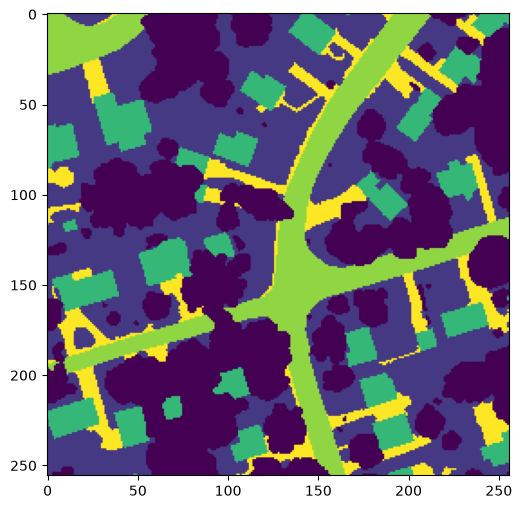

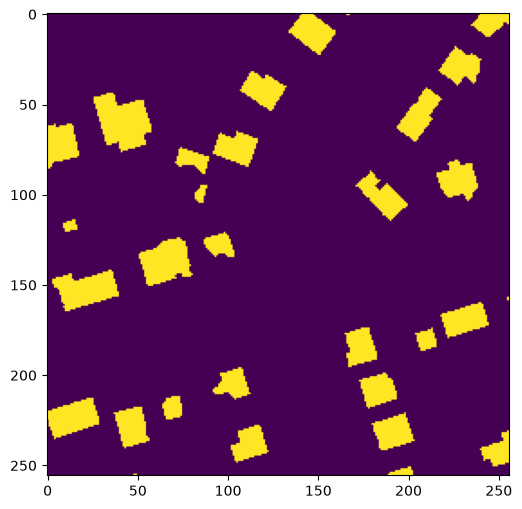

In [8]:
from matplotlib import pyplot as plt

tilefile = str(next(iter(sorted(Path(train_label_folder).glob('*.tif')))))
lu_dataset = rasterio.open(tilefile)
lu_img = lu_dataset.read()
lu_img = lu_img.reshape(lu_img.shape[1], lu_img.shape[2])

plt.figure(figsize=(6, 6))
plt.imshow(lu_img)

plt.figure(figsize=(6, 6))
plt.imshow(lu_img == 5)

In [ ]:
lu_img.shape

### Cut the NAIP into tiles
Here we are going to use the boundary of those landuse tiles to cut the NAIP imagery into tiles.

In [9]:
def naip2tiles(naip_file, lu_folder, naip_tile_folder):
    '''
    Clip the NAIP tiles into tiles based on the size and geoinformation from the 
    clipped land use/cover tiles
    '''
    
    lu_dataset = rasterio.open(naip_file)
    lu_bounds = lu_dataset.bounds
    lu_box = Polygon([(lu_bounds.left, lu_bounds.bottom), \
                      (lu_bounds.left, lu_bounds.top), \
                      (lu_bounds.right, lu_bounds.top), \
                      (lu_bounds.right, lu_bounds.bottom)])
    
    for file in os.listdir(lu_folder):
        basename = os.path.basename(file)
        
        dem_data = rasterio.open(os.path.join(lu_folder, file))
        dem_bounds = dem_data.bounds
        left = dem_bounds.left
        bottom = dem_bounds.bottom
        right = dem_bounds.right
        top = dem_bounds.top    
        
        tile_box = Polygon([(left, bottom), \
                            (left, top), \
                            (right, top), \
                            (right, bottom)])
        
        # check if the dem tile is intersects with the big land use map
        overlap = lu_box.intersects(tile_box)
        if not overlap: continue
        
        # print('The left, botton, right, and top are:', left, bottom, right, top)
        shape = [{'type': 'Polygon', 'coordinates': [[[left, top], [right, top], \
                                                      [right, bottom], [left, bottom], [left, top]]]}]
        
        
        # mask the raster using the polygon, if crop is False, the size would be extremely large
        out_image, out_transform = rasterio.mask.mask(lu_dataset, shape, crop=True)
        
        # prepare the schema of the new tiles
        out_meta = lu_dataset.meta.copy()
        out_meta.update({"driver": "GTiff",
                         "height": out_image.shape[1],
                         "width": out_image.shape[2],
                         "transform": out_transform,
                         "crs": lu_dataset.crs}
                       )
        
        out_tif = os.path.join(naip_tile_folder, basename)
        with rasterio.open(out_tif, "w", **out_meta) as dest:
            dest.write(out_image)
        

In [10]:
train_img_folder = os.path.join(foldertraining, 'imgs')
if not os.path.exists(train_img_folder): os.mkdir(train_img_folder)

naip2tiles(naip_file, train_label_folder, train_img_folder)


We can check what the NAIP tile look like

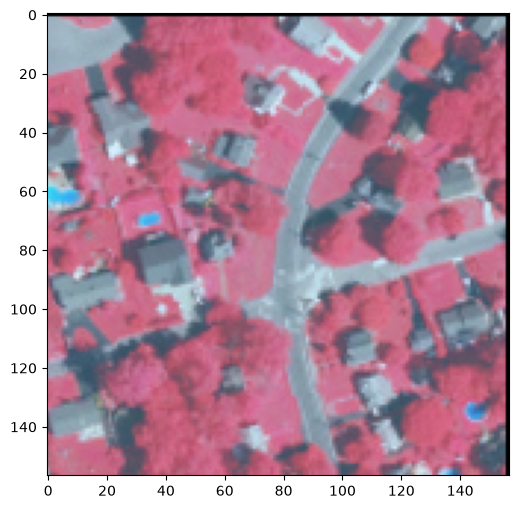

In [11]:
from matplotlib import pyplot as plt

tilefile = str(Path(train_img_folder) / Path(tilefile).name)
naip_dataset = rasterio.open(tilefile)
naip_img = naip_dataset.read()
naip_img = naip_img[:3].transpose(1, 2, 0)  # Display RGB; omit NIR if present.

plt.figure(figsize=(6, 6))
plt.imshow(naip_img)

In [12]:
train_img_folder

'/Users/jianglix/Dropbox/xiaojiang/Teaching/Penn/AI-Urban-Sustainability/ai-urban-sustainability/data/lab9/dataset/trainning/imgs'

In [13]:
naip_img.shape, lu_img.shape


((157, 157, 3), (256, 256))

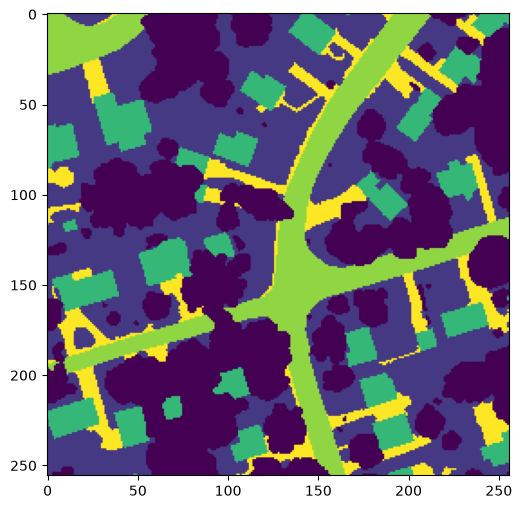

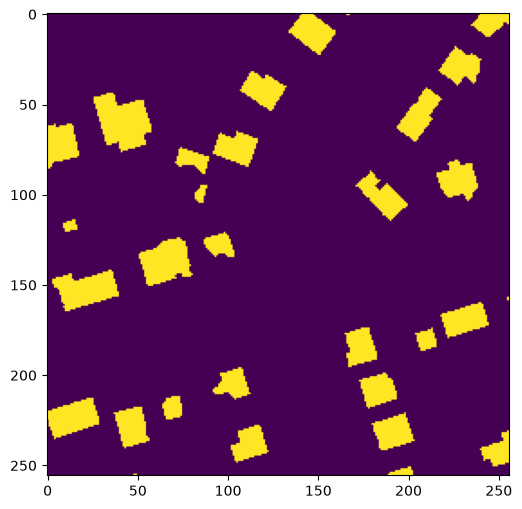

In [14]:
from matplotlib import pyplot as plt

tilefile = str(next(iter(sorted(Path(train_label_folder).glob('*.tif')))))
lu_dataset = rasterio.open(tilefile)
lu_img = lu_dataset.read()
lu_img = lu_img.reshape(lu_img.shape[1], lu_img.shape[2])

plt.figure(figsize=(6, 6))
plt.imshow(lu_img)

plt.figure(figsize=(6, 6))
plt.imshow(lu_img == 5)

In [15]:
# naip_img

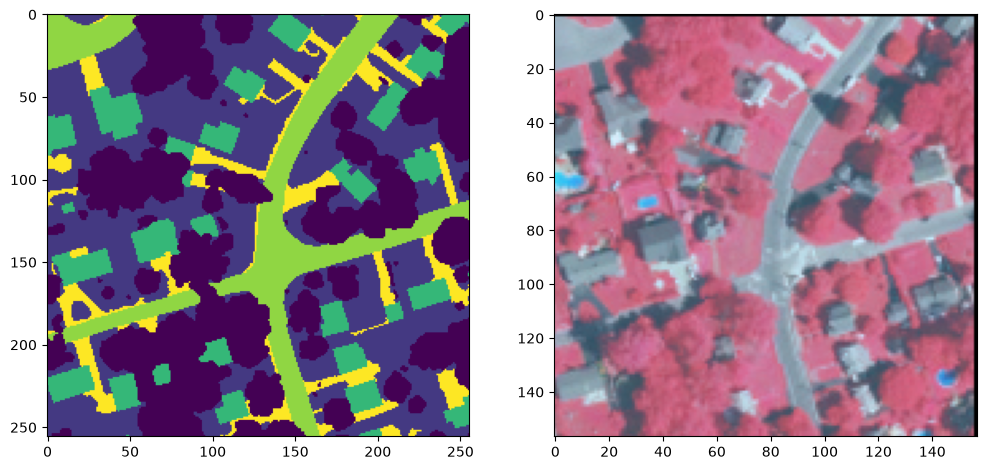

In [16]:
#subplot(r,c) provide the no. of rows and columns
f, axarr = plt.subplots(1, 2, figsize=(12,12)) 

axarr[0].imshow(lu_img)
axarr[1].imshow(naip_img)

### 3. Split the dataset into training and validation

Use a repeatable 80/20 tile split for the building tutorial. Part 2 uses these saved folders directly. The multiclass homework requires a separate spatial train/validation/test split to reduce geographic leakage.


In [17]:
def split_train_validate(training_img_dir, training_labels_dir,
                         validation_img_dir, validation_labels_dir, split=5):
    """Copy paired tiles into a repeatable validation split; retain training files."""
    images = sorted(Path(training_img_dir).glob('*.tif'))
    if len(images) < split:
        raise ValueError('Not enough paired tiles for an 80/20 split.')
    selected = random.Random(42).sample(images, len(images) // split)
    Path(validation_img_dir).mkdir(parents=True, exist_ok=True)
    Path(validation_labels_dir).mkdir(parents=True, exist_ok=True)
    for image in selected:
        label = Path(training_labels_dir) / image.name
        if not label.exists():
            raise FileNotFoundError(label)
        shutil.copy2(image, Path(validation_img_dir) / image.name)
        shutil.copy2(label, Path(validation_labels_dir) / image.name)
    print('Validation tiles:', len(selected))
    print('Part 2 excludes these filenames from its training dataset.')


In [18]:
# the validataon folder
valid_folder = os.path.join(folder1, 'validation')
if not os.path.exists(valid_folder): os.mkdir(valid_folder)
valid_label_folder = os.path.join(valid_folder, 'labels')
if not os.path.exists(valid_label_folder): os.mkdir(valid_label_folder)
valid_img_folder = os.path.join(valid_folder, 'imgs')
if not os.path.exists(valid_img_folder): os.mkdir(valid_img_folder)

split_train_validate(train_img_folder, train_label_folder, valid_img_folder, valid_label_folder)


Validation tiles: 2913
Part 2 excludes these filenames from its training dataset.


In [19]:
folder1

'/Users/jianglix/Dropbox/xiaojiang/Teaching/Penn/AI-Urban-Sustainability/ai-urban-sustainability/data/lab9/dataset'